# Tasks 2 and 3 MapReduce Analytics and Performance

This notebook follows the preparation, sample validation, full YARN execution
and findings in my Word documentation. It covers M1-M3, the self-generated M4,
and three fresh benchmark runs each for M1 and M2.

Saved results and screenshots below come from completed runs. Python cells are
provided for reproduction and local checks and are saved unexecuted. Live job
submission is disabled by default. The longer methods, diagrams and evidence
links remain in [MapReduce_Analytics.md](../userfiles/mapreduce/MapReduce_Analytics.md).

## 1 Working Files and Controls

Use a local Python 3 kernel. Docker Desktop and the setup cluster are required
only for live commands. mrjob runs inside the client, so it need not be installed
in the notebook's local Python environment.

Set **RUN_LIVE = True** to submit jobs. New outputs go to
evidence/notebook-recheck/, leaving the recorded assignment evidence in place.
Set **REBUILD_DATA = True** as well only if rebuilding canonical data from the
four retained raw CSVs. Read-only sample checks use ordinary Python and can run
without Docker.

In [ ]:
from pathlib import Path
from collections import defaultdict, Counter
from fractions import Fraction
from decimal import Decimal, ROUND_HALF_UP
from datetime import datetime, timedelta, timezone
import csv
import json
import re
import subprocess
import time

ROOT = Path.cwd()
if not (ROOT / "docker-compose.yml").exists():
    ROOT = ROOT.parent
assert (ROOT / "docker-compose.yml").exists(), "Open from the project or notebooks folder."
RUN_LIVE = False
REBUILD_DATA = False
SG = timezone(timedelta(hours=8))
SCRIPTS = {"m1": "m1_bus_corridors.py", "m2": "m2_rainfall_station_day.py",
           "m3": "m3_parking_pressure.py", "m4": "m4_rainfall_parking.py"}


def read_csv(relative):
    with (ROOT / relative).open(newline="", encoding="utf-8-sig") as source:
        return list(csv.DictReader(source))


def read_results(path):
    rows = []
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        if line.strip():
            key, value = line.split("\t", 1)
            rows.append((json.loads(key), json.loads(value)))
    return rows


def local_date(value):
    return datetime.fromisoformat(value).astimezone(SG).date().isoformat()


def rounded_fraction(value):
    return (Decimal(value.numerator) / Decimal(value.denominator)).quantize(
        Decimal("0.000001"), rounding=ROUND_HALF_UP)


def run_job(job, runner, inputs, options=()):
    """Run the existing job, or return its saved output path for review."""
    sample = runner == "inline"
    filename = job + ("-sample-output.txt" if sample else "-output.txt")
    args = ["docker", "compose", "exec", "-T", "client", "python3",
            "mapreduce/" + SCRIPTS[job], "-r", runner, *options, *inputs]
    print("Command:", subprocess.list2cmdline(args))
    if not RUN_LIVE:
        print("Job not rerun; reviewing recorded output.")
        return ROOT / "evidence" / job / filename
    folder = ROOT / "evidence" / "notebook-recheck" / job
    folder.mkdir(parents=True, exist_ok=True)
    output = folder / filename
    log = folder / filename.replace("output.txt", "log.txt")
    start = time.perf_counter()
    with output.open("w", encoding="utf-8") as stdout, log.open("w", encoding="utf-8") as stderr:
        result = subprocess.run(args, cwd=ROOT, stdout=stdout, stderr=stderr)
    print("Elapsed seconds:", round(time.perf_counter() - start, 2))
    print("Exit code:", result.returncode)
    if result.returncode:
        raise RuntimeError("Job failed; inspect " + str(log))
    print("Output:", output.relative_to(ROOT))
    return output

print("Project:", ROOT.name, "| Live job submission:", RUN_LIVE)

## 2 Prepare and Upload Canonical Inputs

I first inspected the raw headers, then used one shared preparation script.
It validates values, preserves identifiers as strings, deduplicates observations
and retains rejected records with reason codes. Preparation is separate from
MapReduce aggregation.

| Source | Input | Accepted | Excluded |
|---|---:|---:|---:|
| Bus stops | 5,209 | 5,209 | 0 |
| Bus OD | 5,863,920 | 5,863,920 | 0 |
| Rainfall | 761,445 | 761,445 | 0 |
| Parking | 1,745,692 | 1,727,688 | 18,004 |

Parking exclusions were 3,908 invalid rows and 14,096 repeats. Valid lot types
were preserved before M3/M4 select C. The 7,995 valid OD rows with unmatched
stop metadata were retained.

| Input grain | Important rule |
|---|---|
| Bus OD | Monthly day-type/hour aggregates, not dated journeys; sum passenger counts |
| Rainfall | Unique station/five-minute observations; daily denominator 288 |
| Parking | Unique carpark/lot-type/source-time observations; use each reading's capacity |
| Metadata | Station names/coordinates derived from supplied rainfall; no invented locations |

Rainfall spans September 2026. Parking API responses span September, but source
update times include older dates. M3 groups actual source dates; M4 filters to
September source dates. Parking snapshots are hourly and irregular at carpark
level, not a complete five-minute archive.

The [provenance note](../data_provenance.md) contains source URLs, field mappings,
duplicate rules and missing fields. The [manifest](../userfiles/metadata/manifest.json)
contains locally calculated hashes. A lecturer-issued reference manifest was
not available; that verification is not claimed.

In [ ]:
if REBUILD_DATA:
    assert RUN_LIVE, "Enable RUN_LIVE before rebuilding data."
    subprocess.run(["docker", "compose", "exec", "-T", "client", "python3",
                    "prepare_data.py"], cwd=ROOT, check=True)
else:
    print("Preparation not rerun; using the retained canonical files.")

if RUN_LIVE:
    for local_folder, remote_folder in (("canonical_data", "canonical"),
                                         ("quarantine_data", "quarantine")):
        files = sorted((ROOT / "userfiles" / local_folder).glob("*.csv"))
        assert files, "Missing " + local_folder
        prefix = ["docker", "compose", "exec", "-T", "client", "hdfs", "dfs"]
        remote = "/sg_mobility/" + remote_folder
        subprocess.run(prefix + ["-mkdir", "-p", remote], cwd=ROOT, check=True)
        paths = ["/home/user/" + local_folder + "/" + path.name for path in files]
        subprocess.run(prefix + ["-put", "-f", *paths, remote + "/"], cwd=ROOT, check=True)
else:
    print("HDFS upload not rerun; upload checks and hashes are linked below.")

The prepared [bus](../evidence/data-preparation/bus-prepared-hdfs-files.txt),
[rainfall](../evidence/data-preparation/rainfall-prepared-hdfs-files.txt) and
[parking](../evidence/data-preparation/carpark-prepared-hdfs-files.txt) listings
record the uploads. The later
[HDFS hash verification](../evidence/data-preparation/provenance-hdfs-verification.txt)
confirms all 16 checked HDFS files matched their local copies.

## 3 MapReduce Stages

A mapper emits grouping keys and values. Shuffle groups equal keys for a
reducer. A combiner can reduce traffic locally; it is not a separate stage.
M1/M2 use two stages, M3 one, and M4 three. Stages without custom mappers use
identity forwarding before regrouping. Each Hadoop stage submits its own YARN
application.

## 4 M1 Busiest Directed Bus Corridors

**Question:** For each month and day type, which ten directed stop pairs have
the highest total passenger trips across all hours?

**Business use:** Identify high-demand stop pairs for closer capacity and
connectivity review. A stop pair is not an individual bus-service route.

### Method and Logic

```text
Canonical OD rows
  -> Mapper: (month, day type, origin ID, destination ID), trips
  -> Optional combiner: local trip sum
  -> Shuffle by directed pair
  -> Reducer 1: total trips; change key to (month, day type)
  -> Shuffle by month and day type
  -> Reducer 2: top ten, total descending then both stop IDs ascending
       + bus_stops lookup for origin AND destination descriptions
       + disclose unmatched IDs across all pairs in the group
  -> Ranked results
```

### Sample and Independent Check

I extracted the header plus first ten canonical OD records:

```sh
docker compose exec -T client sh -c "head -n 11 canonical_data/bus_od.csv > mapreduce/m1_canonical_sample.csv"
```

The inline run below uses the stop metadata side file. The next cell calculates
sample totals/rankings with ordinary Python, independently of the mrjob code.

In [ ]:
m1_sample_output = run_job("m1", "inline", ["mapreduce/m1_canonical_sample.csv"],
                           ["--stops", "canonical_data/bus_stops.csv"])

In [ ]:
sample = read_csv("userfiles/mapreduce/m1_canonical_sample.csv")
stop_names = {r["bus_stop_id"]: r["description"]
              for r in read_csv("userfiles/canonical_data/bus_stops.csv")}
reference = Counter()
for row in sample:
    key = (row["year_month"], row["day_type"], row["origin_stop_id"], row["destination_stop_id"])
    reference[key] += int(row["total_trips"])

for group, result in read_results(m1_sample_output):
    expected = sorted([(total, key[2], key[3]) for key, total in reference.items()
                       if list(key[:2]) == group], key=lambda item: (-item[0], item[1], item[2]))[:10]
    actual = [(row["total_trips"], row["origin_stop_id"], row["destination_stop_id"])
              for row in result["top10"]]
    assert actual == expected
    for row in result["top10"]:
        assert row["origin_description"] == stop_names.get(row["origin_stop_id"], "UNMATCHED_STOP")
        assert row["destination_description"] == stop_names.get(row["destination_stop_id"], "UNMATCHED_STOP")
assert len(sample) == 10
assert any(row["origin_stop_id"].startswith("0") for row in sample)
print("M1 passed: ten records, expected seven weekday and three weekend/holiday pairs,")
print("correct totals/tie-breaking, leading zeroes and both endpoint descriptions.")

### Full YARN Execution and Findings

The recorded full run used applications ending **0002 and 0003**, both SUCCEEDED.
The full application-ID prefix throughout this notebook is
`application_1795002805512_`.

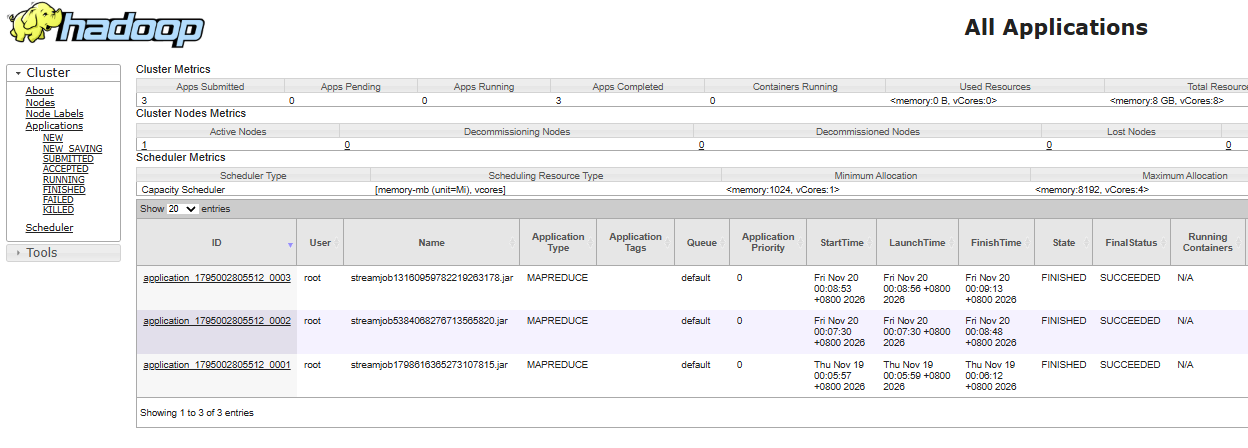

In [ ]:
m1_full_output = run_job("m1", "hadoop", ["hdfs:///sg_mobility/canonical/bus_od.csv"],
                         ["--stops", "canonical_data/bus_stops.csv"])

### Recorded Top Ten 2026-09 WEEKDAY
| Rank | Origin ID | Origin description | Destination ID | Destination description | Trips |
|---|---|---|---|---|---:|
| 1 | 46101 | W'lands Checkpt | 46211 | Johor Bahru Checkpt | 516,385 |
| 2 | 46219 | Johor Bahru Checkpt | 46109 | W'lands Checkpt | 386,367 |
| 3 | 46109 | W'lands Checkpt | 45139 | Kranji Stn | 229,213 |
| 4 | 45139 | Kranji Stn | 46101 | W'lands Checkpt | 171,683 |
| 5 | 47009 | Woodlands Temp Int | 46101 | W'lands Checkpt | 138,450 |
| 6 | 46069 | W'lands Train Checkpt | 46009 | Woodlands Int | 117,227 |
| 7 | 46008 | Woodlands Int | 46069 | W'lands Train Checkpt | 88,703 |
| 8 | 53389 | Opp Bishan Nth Shop Mall | 53231 | Bishan Stn | 68,761 |
| 9 | 46009 | Woodlands Int | 46069 | W'lands Train Checkpt | 64,794 |
| 10 | 63059 | Blk 22 | 63039 | Kovan Stn Exit C | 59,439 |

Unmatched stop IDs: 67689, 67708, 67759.

### Recorded Top Ten 2026-09 WEEKENDS/HOLIDAY
| Rank | Origin ID | Origin description | Destination ID | Destination description | Trips |
|---|---|---|---|---|---:|
| 1 | 46101 | W'lands Checkpt | 46211 | Johor Bahru Checkpt | 194,090 |
| 2 | 46219 | Johor Bahru Checkpt | 46109 | W'lands Checkpt | 163,061 |
| 3 | 46109 | W'lands Checkpt | 45139 | Kranji Stn | 97,620 |
| 4 | 45139 | Kranji Stn | 46101 | W'lands Checkpt | 67,686 |
| 5 | 46069 | W'lands Train Checkpt | 46009 | Woodlands Int | 56,750 |
| 6 | 47009 | Woodlands Temp Int | 46101 | W'lands Checkpt | 49,470 |
| 7 | 46008 | Woodlands Int | 46069 | W'lands Train Checkpt | 34,474 |
| 8 | 46109 | W'lands Checkpt | 47009 | Woodlands Temp Int | 24,231 |
| 9 | 53389 | Opp Bishan Nth Shop Mall | 53231 | Bishan Stn | 21,579 |
| 10 | 46109 | W'lands Checkpt | 46521 | Marsiling Stn | 17,631 |

Unmatched stop IDs: 07522, 44711, 67689, 67759, 70372.

The busiest pair was 46101 (W'lands Checkpt) to 46211 (Johor Bahru Checkpt),
with 516,385 weekday trips and 194,090 weekend/holiday trips. These are monthly
totals within each day type. Only September was analysed, and metadata does not
cover every historic stop.

[Full output](../evidence/m1/m1-output.txt) | [YARN log](../evidence/m1/m1-yarn-log.txt) |
[Sample output](../evidence/m1/m1-sample-output.txt) | [Source](../userfiles/mapreduce/m1_bus_corridors.py)

## 5 M2 Rainfall by Station and Day

**Question:** What are station-day rainfall totals and coverage, and which ten
eligible station-days have the highest observed rainfall?

**Business use:** Identify heavy-rainfall station-days for local disruption
reviews while showing whether the readings provide sufficient coverage.

### Method and Logic

```text
Canonical rainfall rows
  -> Mapper: (station ID, Singapore date), rainfall and count 1
  -> Optional combiner: local rainfall sum and count
  -> Shuffle by station and date
  -> Reducer 1: rainfall total, count, coverage = count / 288
  -> Shuffle daily summaries to common key
  -> Reducer 2: add missing station-days within the reporting scope
       -> daily summaries and separate partial results
       -> rank top ten with at least 260 slots, using station/date tie-breaking
```

Rainfall is never summed across stations into an islandwide depth. Zero readings
count as valid observations; absent readings remain missing.

### Controlled Sample

The sample has 807 actual readings from 22 September: S306 has 288, S904 260,
and S06 259. Deliberate omissions apply only to the sample. This is larger than
ten rows because it tests the daily coverage boundary.

In [ ]:
m2_sample_output = run_job("m2", "inline", ["mapreduce/m2_canonical_sample.csv"])

In [ ]:
reference = defaultdict(lambda: [0, Decimal("0")])
for row in read_csv("userfiles/mapreduce/m2_canonical_sample.csv"):
    key = (row["station_id"], local_date(row["observed_at"]))
    reference[key][0] += 1
    reference[key][1] += Decimal(row["rainfall_mm"])
ranked = []
partial = []
for key, result in read_results(m2_sample_output):
    if key[0] == "daily":
        count, total = reference[(key[1], key[2])]
        assert result["valid_observations"] == count
        assert Decimal(result["total_observed_rainfall_mm"]) == total
        assert result["coverage_percent"] == round(count / 288 * 100, 2)
        assert result["status"] == ("eligible" if count >= 260 else "partial")
    elif key[0] == "top10":
        ranked.append(result["station_id"])
    elif key[0] == "partial":
        partial.append(result["station_id"])
assert ranked == ["S306", "S904"] and partial == ["S06"]
print("M2 passed: S306 130.6 mm / 100%; S904 123.2 mm / 90.28%;")
print("S06 47.4 mm / 89.93%, correctly excluded from ranking and retained as partial.")

### Full YARN Execution and Findings

Applications ending **0004 and 0005** both SUCCEEDED.

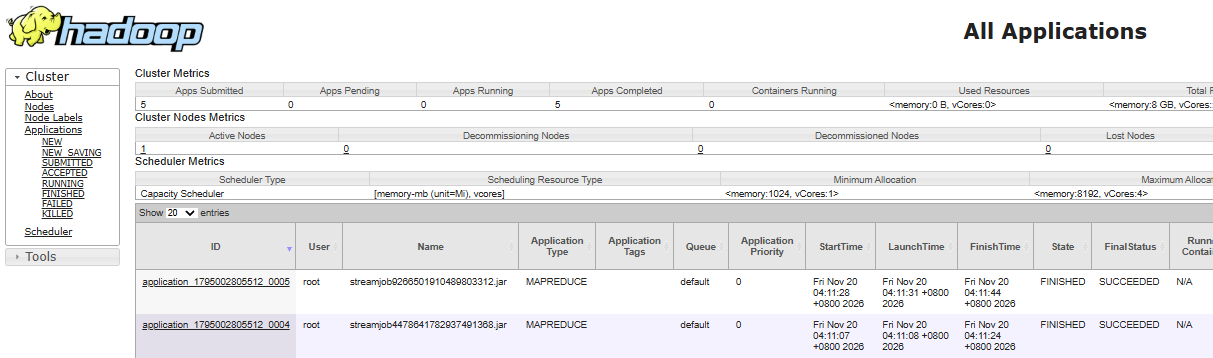

In [ ]:
m2_full_output = run_job("m2", "hadoop", ["hdfs:///sg_mobility/canonical/rainfall.csv"])

### Recorded Top Ten Eligible Station-Days
| Rank | Station ID and name | Date | Rainfall (mm) | Coverage |
|---|---|---|---:|---:|
| 1 | S306 Murnane Service Reservoir | 2026-09-22 | 130.6 | 100.0% |
| 2 | S904 Holland Grove Road | 2026-09-22 | 123.2 | 100.0% |
| 3 | S904 Holland Grove Road | 2026-09-27 | 121.0 | 100.0% |
| 4 | S903 Lorong Kismis | 2026-09-22 | 120.0 | 100.0% |
| 5 | S50 Clementi Road | 2026-09-22 | 118.4 | 100.0% |
| 6 | S213 Coronation Walk | 2026-09-22 | 117.6 | 100.0% |
| 7 | S50 Clementi Road | 2026-09-27 | 115.2 | 100.0% |
| 8 | S71 Kent Ridge Road | 2026-09-27 | 114.2 | 100.0% |
| 9 | S201 Sunset Way | 2026-09-22 | 111.4 | 100.0% |
| 10 | S187 Coronation Road | 2026-09-22 | 110.4 | 100.0% |

S306 recorded the largest eligible daily total, 130.6 mm on 22 September.
Of 2,670 reported station-days, 2,631 were eligible, 23 were partially observed
and 16 had no readings. The reporting scope uses input station IDs and the
first/last dates; station operating dates were unavailable. Missing intervals
can underestimate rainfall even when coverage reaches 90%.

[Full output](../evidence/m2/m2-output.txt) | [YARN log](../evidence/m2/m2-yarn-log.txt) |
[Sample output](../evidence/m2/m2-sample-output.txt) | [Source](../userfiles/mapreduce/m2_rainfall_station_day.py)

## 6 M3 Parking Pressure by Carpark and Day

**Question:** For car lot type C, what are each carpark-day's mean occupancy,
maximum occupancy and fraction of valid unique observations at least 90% full?

**Business use:** Identify days with parking pressure that a daily average alone
might hide.

### Method and Logic

```text
Canonical parking rows
  -> Mapper: retain C; validate positive capacity and valid availability
       occupancy = (capacity - available) / capacity
       key = (carpark ID, Singapore source date)
  -> Optional combiner: counts, occupancy sums, maximum and threshold count
  -> Shuffle by carpark and source date
  -> Reducer: count, mean, maximum and fraction at least 90%
```

Each observation uses its own capacity. Only one stage is needed because all
statistics use the same key. The combiner preserves sums and counts rather than
averaging averages.

### Sample and Independent Check

I extracted the header and first ten canonical parking records:

```sh
docker compose exec -T client sh -c "head -n 11 canonical_data/carpark.csv > mapreduce/m3_canonical_sample.csv"
```

In [ ]:
m3_sample_output = run_job("m3", "inline", ["mapreduce/m3_canonical_sample.csv"])

In [ ]:
reference = defaultdict(list)
for row in read_csv("userfiles/mapreduce/m3_canonical_sample.csv"):
    if row["lot_type"] != "C":
        continue
    capacity = int(row["total_lots"])
    occupied = capacity - int(row["lots_available"])
    reference[(row["carpark_id"], local_date(row["observed_at"]))].append(Fraction(occupied, capacity))
for key, result in read_results(m3_sample_output):
    values = reference[tuple(key)]
    assert result["valid_observations"] == len(values)
    assert Decimal(result["mean_occupancy_ratio"]) == rounded_fraction(sum(values) / len(values))
    assert Decimal(result["max_occupancy_ratio"]) == rounded_fraction(max(values))
    pressure = sum(value >= Fraction(9, 10) for value in values)
    assert Decimal(result["fraction_at_least_90_percent"]) == rounded_fraction(Fraction(pressure, len(values)))
print("M3 passed: A10 on 31 August has one reading, mean 0.625000;")
print("1 September has nine, mean 0.592014; neither group reaches 90%.")

The sample checks aggregation and source-date grouping. It does not exercise
the 90% boundary, different lot types or changing capacities.

### Full YARN Execution and Findings

Application ending **0006** SUCCEEDED.

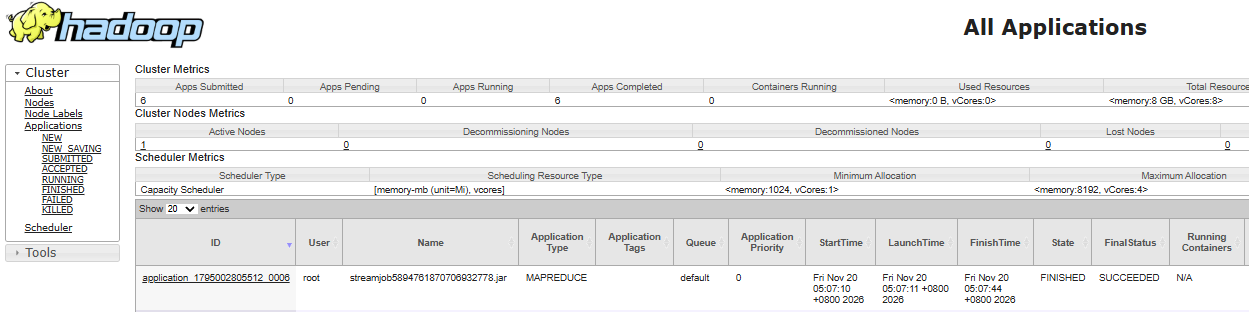

In [ ]:
m3_full_output = run_job("m3", "hadoop", ["hdfs:///sg_mobility/canonical/carpark.csv"])

The full output contains 61,669 carpark-day summaries. An illustrative result:

| A10 on 3 September 2026 | Value |
|---|---:|
| Valid observations | 24 |
| Mean occupancy | 60.42% |
| Maximum occupancy | 100% |
| Observations at least 90% full | 3 |
| Fraction at least 90% full | 12.5% |

A moderate mean can hide periods of high observed pressure. These measures are
sample-weighted; 12.5% of observations does not establish 12.5% of the day when
sampling is irregular. Snapshots do not measure vehicle arrivals or duration.
Older source dates remain assigned to those dates, even when response dates
fall in September.

[Full output](../evidence/m3/m3-output.txt) | [YARN log](../evidence/m3/m3-yarn-log.txt) |
[Sample output](../evidence/m3/m3-sample-output.txt) | [Source](../userfiles/mapreduce/m3_parking_pressure.py)

## 7 M4 Self-Generated Integrated Question

**Which carparks show the largest differences in mean observed daily occupancy
between widespread-rainfall days and days with no recorded rainfall among
eligible stations during September 2026?**

### Business Justification

Parking operators can use this analysis to identify carparks whose observed
occupancy differs between regional weather conditions and prioritise locations
for further operational review. The analysis compares mean daily occupancy
within each carpark, reporting supporting day and observation counts. It provides
exploratory evidence for reviewing wet-weather parking guidance and capacity
management. Regional rainfall does not establish rainfall at individual carparks,
and differences may also reflect weekday patterns, events and uneven sampling.

### Declared Rules

| Rule | Definition |
|---|---|
| Period | September 2026 source dates in Singapore time |
| Eligible station-day | At least 260 unique five-minute readings |
| Widespread rainfall | At least 50% of eligible stations recorded rainfall above zero |
| No recorded rainfall | No eligible station recorded rainfall above zero |
| Other dates | Exclude intermediate proportions and days without eligible stations |
| Parking | Valid lot type C; average observations within each carpark-day |
| Group mean | Average daily means, giving every contributing day equal weight |
| Minimum support | Three days in each weather group per carpark |
| Difference | Rainfall-group mean minus no-recorded-rainfall-group mean, multiplied by 100 |
| Ranking | Top ten absolute unrounded differences; carpark ID breaks ties |

The 50% and three-day thresholds are analysis choices, not statistical tests.
This joins regional weather context and parking by date, without assigning
individual carparks to rainfall stations or inventing coordinates.

### MapReduce Logic

```text
Rainfall + parking canonical rows
  -> Stage 1 mapper: tag records; group by type, source date and station/carpark
  -> Combiner + reducer: eligible station-day rain indicators and carpark-day means
  -> Stage 2 shuffle by date
  -> Reducer: calculate eligible-station rain proportion; classify date
       join parking summaries to that weather group; exclude other dates
  -> Stage 3 shuffle summaries to common key
  -> Reducer: compare daily means per carpark, require three days per group
       emit all qualifying comparisons and top ten absolute differences
```

The final reducer retains per-carpark summaries instead of raw observations.
It provides global ranking on the classroom workload, not unlimited scalability.

### Controlled Sample

The script's --create-sample option selects actual records from 3, 4, 5, 21, 22
and 27 September. The rainfall sample has 1,727 S306 readings. The parking sample
has 262 A10/A11 observations; A11's 27 September readings are deliberately omitted.
The one-station sample tests logic, not full-network weather classifications.

```sh
docker compose exec -T client python3 mapreduce/m4_rainfall_parking.py --create-sample
```

In [ ]:
m4_sample_output = run_job("m4", "inline", ["mapreduce/m4_sample_rainfall.csv",
                                          "mapreduce/m4_sample_carpark.csv"])

In [ ]:
rain = defaultdict(list)
for row in read_csv("userfiles/mapreduce/m4_sample_rainfall.csv"):
    rain[(row["station_id"], local_date(row["observed_at"]))].append(Fraction(row["rainfall_mm"]))
weather = defaultdict(list)
for (station, day), readings in rain.items():
    if len(readings) >= 260:
        weather[day].append(sum(readings) > 0)
categories = {day: ("no_recorded_rainfall" if not any(flags)
                   else "widespread_rainfall" if 2 * sum(flags) >= len(flags)
                   else "intermediate") for day, flags in weather.items()}
parking = defaultdict(list)
for row in read_csv("userfiles/mapreduce/m4_sample_carpark.csv"):
    if row["lot_type"] == "C":
        capacity = int(row["total_lots"])
        key = (row["carpark_id"], local_date(row["observed_at"]))
        parking[key].append(Fraction(capacity - int(row["lots_available"]), capacity))
groups = defaultdict(lambda: defaultdict(list))
for (carpark, day), values in parking.items():
    category = categories.get(day)
    if category in ("widespread_rainfall", "no_recorded_rainfall"):
        groups[carpark][category].append((sum(values) / len(values), len(values)))
expected = {}
for carpark, group in groups.items():
    wet = group.get("widespread_rainfall", [])
    no_rain = group.get("no_recorded_rainfall", [])
    if min(len(wet), len(no_rain)) >= 3:
        expected[carpark] = (wet, no_rain)
assert set(expected) == {"A10"}
for key, result in read_results(m4_sample_output):
    carpark = result["carpark_id"]
    wet, no_rain = expected[carpark]
    wet_mean = sum(value for value, count in wet) / len(wet)
    no_rain_mean = sum(value for value, count in no_rain) / len(no_rain)
    assert result["widespread_rainfall_days"] == len(wet)
    assert result["no_recorded_rainfall_days"] == len(no_rain)
    assert result["widespread_rainfall_observations"] == sum(count for value, count in wet)
    assert result["no_recorded_rainfall_observations"] == sum(count for value, count in no_rain)
    assert Decimal(result["difference_percentage_points"]) == rounded_fraction((wet_mean - no_rain_mean) * 100)
    assert Decimal(result["widespread_rainfall_mean_occupancy_ratio"]) == rounded_fraction(wet_mean)
    assert Decimal(result["no_recorded_rainfall_mean_occupancy_ratio"]) == rounded_fraction(no_rain_mean)
print("M4 passed: only A10 qualifies, with three days / 72 observations per group.")
print("Means: 0.481554 versus 0.544271; signed difference: -6.271701 percentage points.")
print("A11 is excluded because it has only two rainfall days in the sample.")

### Full YARN Execution and Findings

Applications ending **0007, 0008 and 0009** all SUCCEEDED.

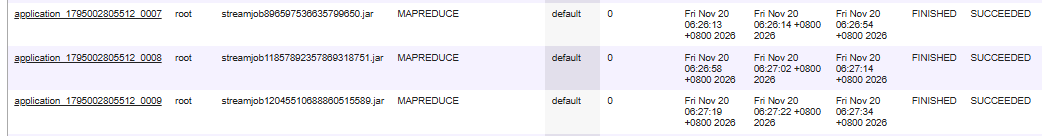

In [ ]:
m4_full_output = run_job("m4", "hadoop", ["hdfs:///sg_mobility/canonical/rainfall.csv",
                                          "hdfs:///sg_mobility/canonical/carpark.csv"])

### Recorded Top Ten Differences
| Rank | Carpark | Rainfall-group mean | No-recorded-rainfall-group mean | Difference (percentage points) | Days rain / no rain |
|---|---|---:|---:|---:|---:|
| 1 | EPL | 59.19% | 89.48% | -30.29 | 9 / 12 |
| 2 | U24 | 61.89% | 32.37% | 29.52 | 9 / 12 |
| 3 | T3 | 51.03% | 25.00% | 26.02 | 9 / 12 |
| 4 | C17 | 39.81% | 15.08% | 24.73 | 9 / 12 |
| 5 | CK66 | 15.28% | 39.84% | -24.55 | 9 / 12 |
| 6 | L8 | 75.19% | 50.84% | 24.34 | 9 / 12 |
| 7 | SB46 | 44.04% | 20.25% | 23.79 | 9 / 12 |
| 8 | T1 | 43.84% | 21.53% | 22.30 | 9 / 12 |
| 9 | HG53 | 52.22% | 74.35% | -22.13 | 7 / 11 |
| 10 | U5 | 46.59% | 25.06% | 21.53 | 9 / 12 |

There were nine widespread-rainfall dates, twelve no-recorded-rainfall dates
and nine intermediate dates excluded. A total of 1,996 carparks qualified;
four represented on retained weather dates failed the supporting-day minimum.

EPL had the largest absolute difference: 59.19% versus 89.48%, a difference of
-30.29 percentage points, using 214 and 289 observations across nine and twelve
days. U24 showed the opposite direction, with occupancy higher by 29.52 points.
This suggests locations for closer review rather than a uniform rainfall effect.

**Limitations:** station proportions do not measure geographic area or rainfall
at individual carparks. Eligible stations vary by day, and missing slots can
hide rain. Uneven sampling, weekday/weekend patterns and events can affect
occupancy. Three days per group is a support filter, not proof of significance.
The comparison establishes associations, not causation.

[Full output](../evidence/m4/m4-output.txt) | [YARN log](../evidence/m4/m4-yarn-log.txt) |
[Sample output](../evidence/m4/m4-sample-output.txt) | [Source](../userfiles/mapreduce/m4_rainfall_parking.py)

## 8 Verify Repeated-Run Output Consistency

The following compares records rather than line order. This checks that every
retained benchmark produced the same result as the validated full run; it is
separate from the independently calculated sample checks above.

In [ ]:
def normalised_records(path):
    return sorted(json.dumps([key, value], sort_keys=True) for key, value in read_results(path))

for job in ("m1", "m2"):
    baseline = normalised_records(ROOT / "evidence" / job / (job + "-output.txt"))
    for number in range(1, 4):
        path = ROOT / "evidence" / "performance analysis" / job / f"{job}-benchmark-run{number}-output.txt"
        assert normalised_records(path) == baseline
        print(job.upper(), "benchmark", number, "matches the validated output")

## 9 Task 3 Performance Analysis

### Explanation

I ran M1 (bus corridors) and M2 (rainfall) three times each using unchanged inputs and cluster settings. Timings include submission, both stages and saving results. The cluster stayed running; I did not restart services or clear cached data between runs.

M1's median runtime was 124.97 seconds, with a range of 1.39 seconds. M2's median was 54.92 seconds, with a range of 0.97 seconds. These small ranges show similar timings across repeated runs.

M1 processed about 222 MB and shuffled 289.50 MB, compared with M2's 27 MB input and 0.62 MB shuffle. Shuffle transfers and groups mapper output for reducers. This additional work helps explain M1's longer runtime. Both analyses used two stages and one reducer per stage, limiting parallel reducer work. The single NodeManager's memory and CPU resources limited how many tasks could run together.

During troubleshooting, I corrected the commands to record both start and end times, then excluded interrupted attempts. All six outputs matched validated results. I did not change resources or test scaling. The results show runtime and variation on this cluster, but do not establish that adding nodes would improve performance or that input size alone caused the difference.

### Timing Results

All times are seconds. Median means the middle value after sorting the three
runtimes. Range means the longest runtime minus the shortest.

| Analysis | Run 1 | Run 2 | Run 3 | Median | Range |
|---|---:|---:|---:|---:|---:|
| M1 - Bus corridors | 124.97 | 123.90 | 125.29 | 124.97 | 1.39 |
| M2 - Rainfall | 54.92 | 55.24 | 54.27 | 54.92 | 0.97 |

### Run Evidence

Each run returned exit code 0 and both applications completed successfully.
All application IDs below use the prefix application_1795002805512_.

| Run | Application suffixes, stages 1 / 2 | Complete timing | Task and resource counters | Application status screenshot |
|---|---|---|---|---|
| M1 1 | 0014 / 0015 | [Timing](../evidence/performance%20analysis/m1/m1-benchmark-run1-timing.txt) | [Log](../evidence/performance%20analysis/m1/m1-benchmark-run1-log.txt) | [YARN](../evidence/performance%20analysis/m1/m1-benchmark1-yarn-applications.png) |
| M1 2 | 0016 / 0017 | [Timing](../evidence/performance%20analysis/m1/m1-benchmark-run2-timing.txt) | [Log](../evidence/performance%20analysis/m1/m1-benchmark-run2-log.txt) | [YARN](../evidence/performance%20analysis/m1/m1-benchmark2-yarn-applications.png) |
| M1 3 | 0018 / 0019 | [Timing](../evidence/performance%20analysis/m1/m1-benchmark-run3-timing.txt) | [Log](../evidence/performance%20analysis/m1/m1-benchmark-run3-log.txt) | [YARN](../evidence/performance%20analysis/m1/m1-benchmark3-yarn-applications.png) |
| M2 1 | 0020 / 0021 | [Timing](../evidence/performance%20analysis/m2/m2-benchmark-run1-timing.txt) | [Log](../evidence/performance%20analysis/m2/m2-benchmark-run1-log.txt) | [YARN](../evidence/performance%20analysis/m2/m2-benchmark1-yarn-applications.png) |
| M2 2 | 0022 / 0023 | [Timing](../evidence/performance%20analysis/m2/m2-benchmark-run2-timing.txt) | [Log](../evidence/performance%20analysis/m2/m2-benchmark-run2-log.txt) | [YARN](../evidence/performance%20analysis/m2/m2-benchmark2-yarn-applications.png) |
| M2 3 | 0024 / 0025 | [Timing](../evidence/performance%20analysis/m2/m2-benchmark-run3-timing.txt) | [Log](../evidence/performance%20analysis/m2/m2-benchmark-run3-log.txt) | [YARN](../evidence/performance%20analysis/m2/m2-benchmark3-yarn-applications.png) |

### Task and Container Evidence

The saved logs contain map/reduce counts, shuffle totals and allocated memory
and CPU resource-time counters for every stage of every run. All stages used
one reducer. The table below summarises the task and shuffle counters.
MB means 1,000,000 bytes.

| Run | Stage 1 map attempts | Stage 2 map attempts | Shuffled data across both stages (MB) |
|---|---:|---:|---:|
| M1 1 | 53 | 8 | 289.50 |
| M1 2 | 53 | 8 | 289.50 |
| M1 3 | 54 | 8 | 289.50 |
| M2 1 | 7 | 2 | 0.62 |
| M2 2 | 7 | 2 | 0.62 |
| M2 3 | 7 | 2 | 0.62 |

M1 run 3 recorded one killed map attempt and an extra launch. The job still
succeeded and its output matched the validated result. The log does not
establish why that attempt was killed. Attempt counts do not mean all tasks
ran at the same time.

### Recalculate Timings from the Saved Files

These calculations use the recorded Windows start/end timestamps, including
submission and output retrieval. They do not launch new benchmark jobs.
The original setup timings and interrupted attempts are excluded.

In [ ]:
from statistics import median

for job in ("m1", "m2"):
    runtimes = []
    for number in range(1, 4):
        folder = ROOT / "evidence" / "performance analysis" / job
        text = (folder / f"{job}-benchmark-run{number}-timing.txt").read_text()
        assert "ExitCode 0" in text
        def timestamp(label):
            match = re.search(label + r"\s+\w+\s+(\d{2}/\d{2}/\d{4})\s+(\d{1,2}:\d{2}:\d{2}\.\d+)", text)
            return datetime.strptime(" ".join(match.groups()), "%d/%m/%Y %H:%M:%S.%f")
        elapsed = (timestamp("End") - timestamp("Start")).total_seconds()
        runtimes.append(round(elapsed, 2))
    print(job.upper(), "runs:", runtimes, "median:", median(runtimes),
          "range:", round(max(runtimes) - min(runtimes), 2))

## 10 Supporting Records

- [Data provenance](../data_provenance.md): sources, periods, schemas, counts, missing fields and cadence.
- [Manifest](../userfiles/metadata/manifest.json): locally calculated file hashes and HDFS paths.
- [Analytics write-up](../userfiles/mapreduce/MapReduce_Analytics.md): full methods, rules and Mermaid diagrams.
- [Performance write-up](../performance_analysis.md): 193-word interpretation and evidence tables.
- [Debugging journal](../debugging_journal.md): genuine issues and controlled tests.
- [Evidence guide](../evidence/README.md): organisation and historical paths.

The code used to solve the analyses remains in userfiles/mapreduce/. This
notebook organises explanations, reproducible commands and validation alongside
the recorded results; it does not replace the original evidence files.